<a href="https://colab.research.google.com/github/DS-3001-Group-15/L02-hedonic-pricing/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Mouad Tazka, Charlotte Olexy, Maya Yonathan

**Date:** 11/10/2026

Q1.

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

raw = pd.read_csv("pierce_county_house_sales.csv")
raw["sale_date"] = pd.to_datetime(raw["sale_date"], errors="coerce")
print("Original shape:", raw.shape)
display(raw.head())

Original shape: (16814, 19)


,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,interior,stories,roof_cover,year_built,bedrooms,bathrooms,waterfront_type,view_quality,utility_sewer
0,2020-01-02,380000,2157,0,0,528,0,0,Warm and Cool Air Zone,Frame Siding,Drywall,2,Composition Shingle,1993,3,3,NaN,NaN,SEWER/SEPTIC INSTALLED
1,2020-01-02,383000,2238,0,0,396,0,0,Forced Air,Frame Siding,Drywall,2,Composition Shingle,2017,4,3,NaN,NaN,SEWER/SEPTIC INSTALLED
2,2020-01-01,419900,1452,0,0,0,0,1,Forced Air,Frame Siding,Drywall,1,Built Up Rock,1965,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED
3,2020-01-02,251660,832,0,0,0,0,0,Forced Air,Frame Vinyl,Drywall,1,Composition Shingle,1919,2,1,NaN,NaN,SEWER/SEPTIC INSTALLED
4,2020-01-02,500000,1780,0,384,484,0,1,Forced Air,Frame Siding,Drywall,1,Composition Shingle,1955,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED


In [36]:
print("Exact duplicate rows:", raw.duplicated().sum())
print("\nMissing values by column:")
display(raw.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

print("\nNumeric summary before cleaning:")
display(raw.describe().round(1))

Exact duplicate rows: 46

Missing values by column:


,missing_count
waterfront_type,16261
view_quality,15895
roof_cover,8
hvac_description,7
interior,7
exterior,1
sale_date,0
house_square_feet,0
sale_price,0
detached_garage_square_feet,0



Numeric summary before cleaning:


,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,year_built,bedrooms,bathrooms
count,16814,16814.0,16814.0,16814.0,16814.0,16814.0,16814.0,16814.0,16814.0,16814.0,16814.0,16814.0
mean,2020-07-16 13:34:32.986796,461233.2,1879.9,24.9,167.9,364.4,38.3,0.9,1.6,1980.5,3.3,2.3
min,2020-01-01 00:00:00,2000.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1880.0,0.0,0.0
25%,2020-04-27 00:00:00,348000.0,1320.0,0.0,0.0,0.0,0.0,1.0,1.0,1959.0,3.0,2.0
50%,2020-07-27 00:00:00,416500.0,1774.0,0.0,0.0,420.0,0.0,1.0,2.0,1990.0,3.0,2.0
75%,2020-10-09 00:00:00,523806.5,2352.0,0.0,0.0,528.0,0.0,1.0,2.0,2006.0,4.0,3.0
max,2020-12-31 00:00:00,6130000.0,9510.0,1212.0,4000.0,2816.0,3664.0,5.0,3.0,2021.0,25.0,8.0
std,NaN,236083.3,760.4,102.1,429.1,286.5,164.7,0.6,0.5,33.3,0.9,0.8


I removed exact duplicate rows and a small number of records with clearly questionable values. My checks were: positive sale price; at least 200 square feet; 1 to 3 stories; construction year between 1800 and the sale year; at most 10 bedrooms; and 0 to 8 bathrooms. I kept zero bedrooms or bathrooms because those might reflect studios or incomplete assessments, and I do not have enough information to confidently delete them. I also kept expensive houses instead of arbitrarily removing them as outliers.

For categorical fields, I used Not recorded for blank entries. I did not assume that a blank waterfront or view entry proves that a home has no waterfront or view. I fixed a small spelling inconsistency in hvac_description. Because there is no property ID, exact duplicates could theoretically be separate sales; I treat them as duplicates for this exercise and record the decision.

In [37]:
df = raw.drop_duplicates().copy()
after_duplicates = len(df)

valid = (
        df["sale_date"].notna()
        & (df["sale_price"] > 0)
        & (df["house_square_feet"] >= 200)
        & df["stories"].between(1, 3)
        & df["year_built"].between(1800, df["sale_date"].dt.year)
        & df["bedrooms"].between(0, 10)
        & df["bathrooms"].between(0, 8)
)
df = df.loc[valid].copy()

# Turn blank categories into a real label rather than deleting most of the data.
categorical_cols = df.select_dtypes(
    include=["object", "string"]
).columns.tolist()
for col in categorical_cols:
    df[col] = (
        df[col].astype("string").str.strip()
        .replace("", pd.NA).fillna("Not recorded").astype(str)
    )
df["hvac_description"] = df["hvac_description"].replace(
    {"Floor Wall Furnace": "Floor/Wall Furnace"}
)

print("Original rows:", len(raw))
print("Exact duplicates removed:", len(raw) - after_duplicates)
print("Additional invalid rows removed:", after_duplicates - len(df))
print("Rows remaining:", len(df))
print("Missing values remaining:", df.isna().sum().sum())
print("Median price: ${:,.0f}".format(df["sale_price"].median()))
print("Mean price: ${:,.0f}".format(df["sale_price"].mean()))

display(df[["sale_price", "house_square_feet", "bedrooms", "bathrooms", "year_built"]].describe().round(1))

Original rows: 16814
Exact duplicates removed: 46
Additional invalid rows removed: 83
Rows remaining: 16685
Missing values remaining: 0
Median price: $416,000
Mean price: $460,909


,sale_price,house_square_feet,bedrooms,bathrooms,year_built
count,16685.0,16685.0,16685.0,16685.0,16685.0
mean,460909.2,1877.9,3.3,2.3,1980.2
std,235671.4,759.1,0.9,0.8,33.3
min,2000.0,200.0,0.0,0.0,1880.0
25%,348000.0,1318.0,3.0,2.0,1958.0
50%,416000.0,1773.0,3.0,2.0,1990.0
75%,523000.0,2348.0,4.0,3.0,2006.0
max,6130000.0,9510.0,9.0,8.0,2020.0


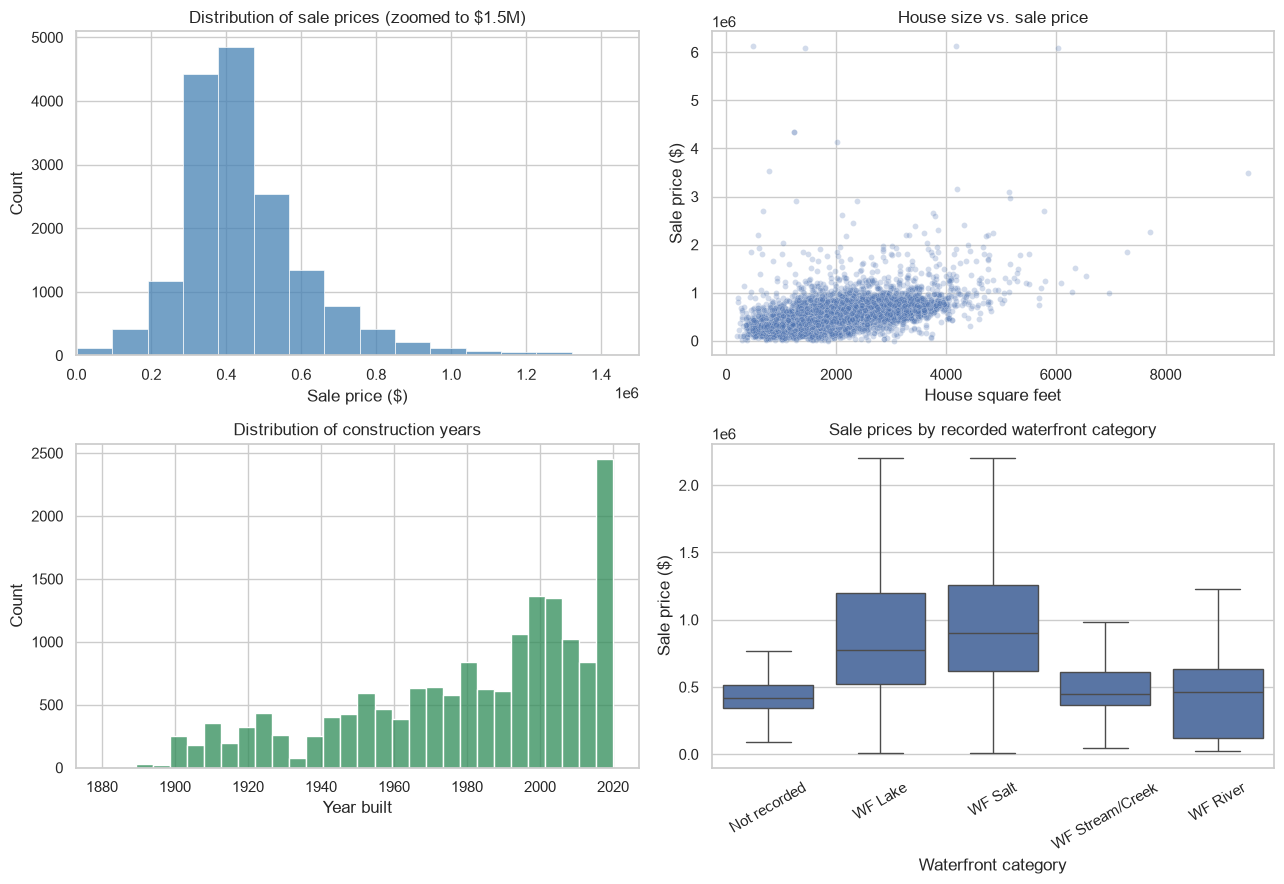

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.histplot(df["sale_price"], bins=65, ax=axes[0, 0], color="steelblue")
axes[0, 0].set_xlim(0, 1_500_000)
axes[0, 0].set_title("Distribution of sale prices (zoomed to $1.5M)")
axes[0, 0].set_xlabel("Sale price ($)")

sns.scatterplot(data=df, x="house_square_feet", y="sale_price", ax=axes[0, 1],
                alpha=0.25, s=18)
axes[0, 1].set_title("House size vs. sale price")
axes[0, 1].set_xlabel("House square feet")
axes[0, 1].set_ylabel("Sale price ($)")

sns.histplot(df["year_built"], bins=30, ax=axes[1, 0], color="seagreen")
axes[1, 0].set_title("Distribution of construction years")
axes[1, 0].set_xlabel("Year built")

sns.boxplot(data=df, x="waterfront_type", y="sale_price", showfliers=False,
            ax=axes[1, 1])
axes[1, 1].set_title("Sale prices by recorded waterfront category")
axes[1, 1].set_xlabel("Waterfront category")
axes[1, 1].set_ylabel("Sale price ($)")
axes[1, 1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig("pierce_county_phase1_eda.png", dpi=150, bbox_inches="tight")
plt.show()

In [39]:
print("Correlations with sale price (numeric variables):")
correlations = df.select_dtypes(include="number").corr()["sale_price"].sort_values(ascending=False)
display(correlations.to_frame("correlation_with_price").round(3))

print("Number of sales and median price for each waterfront category:")
display(df.groupby("waterfront_type")["sale_price"].agg(["count", "median"]).round(0))

Correlations with sale price (numeric variables):


,correlation_with_price
sale_price,1.000
house_square_feet,0.529
bathrooms,0.412
fireplaces,0.349
attached_garage_square_feet,0.312
basement_square_feet,0.271
year_built,0.230
bedrooms,0.209
stories,0.172
detached_garage_square_feet,0.053


Number of sales and median price for each waterfront category:


,count,median
waterfront_type,,
Not recorded,16136,415000.0
WF Lake,225,775000.0
WF River,26,462500.0
WF Salt,205,900000.0
WF Stream/Creek,93,450000.0


The median price is about 416,000 dollars, compared with a mean near 461,000 dollars. The mean is higher because there are some very expensive homes, so the distribution is right-skewed. The scatterplot and correlations suggest that larger houses tend to sell for more. In this dataset, house square footage has a correlation of about 0.529 with price, followed by bathrooms (about 0.412). The waterfront categories also show some price differences, especially for lake and saltwater properties, but these are associations, not proof of causation. I also noticed that a few extreme sales could affect linear regression results.

Q2.

In [40]:
target_col = "sale_price"
X = df.drop(columns=[target_col, "sale_date"])
y = df[target_col]

numeric_cols = X.select_dtypes(include="number").columns.tolist()
categorical_cols = X.select_dtypes(
    include=["object", "string"]
).columns.tolist()

print("Target:", target_col)
print("Numeric predictors:", numeric_cols)
print("Categorical predictors:", categorical_cols)
print("Total original predictors:", X.shape[1])

Target: sale_price
Numeric predictors: ['house_square_feet', 'attic_finished_square_feet', 'basement_square_feet', 'attached_garage_square_feet', 'detached_garage_square_feet', 'fireplaces', 'stories', 'year_built', 'bedrooms', 'bathrooms']
Categorical predictors: ['hvac_description', 'exterior', 'interior', 'roof_cover', 'waterfront_type', 'view_quality', 'utility_sewer']
Total original predictors: 17


Q3.

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))
print("Training percent: {:.1f}%".format(100 * len(X_train) / len(X)))
print("Test percent: {:.1f}%".format(100 * len(X_test) / len(X)))
assert len(X_train) + len(X_test) == len(X)
assert set(X_train.index).isdisjoint(set(X_test.index))

Training observations: 13348
Test observations: 3337
Training percent: 80.0%
Test percent: 20.0%


Q4.

In [42]:
import warnings

warnings.filterwarnings(
    "ignore",
    message=r"Found unknown categories in columns .*",
    category=UserWarning,
    module=r"sklearn\.preprocessing\._encoders"
)

models = {
    "Model 1: Size only": ["house_square_feet"],
    "Model 2: Basic features": ["house_square_feet", "bedrooms", "bathrooms", "year_built"],
    "Model 3: All features": list(X.columns),
}

# This helper uses only dummy encoding for categories, with numeric data untouched.
def make_linear_model(feature_names):
    cat_features = [col for col in feature_names if col in categorical_cols]
    num_features = [col for col in feature_names if col in numeric_cols]
    steps = [("numeric", "passthrough", num_features)]
    if cat_features:
        steps.append((
            "categorical",
            OneHotEncoder(drop="first", handle_unknown="ignore"),
            cat_features
        ))
    preprocessor = ColumnTransformer(steps)
    return Pipeline([
        ("preprocessor", preprocessor),
        ("regression", LinearRegression())
    ])

cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = {}
for name, features in models.items():
    model = make_linear_model(features)
    scores = cross_val_score(
        model, X_train[features], y_train,
        cv=cv, scoring="neg_root_mean_squared_error"
    )
    cv_scores[name] = -scores.mean()

best_model_name = min(cv_scores, key=cv_scores.get)
print("Training-only 5-fold validation RMSE:")
for name, value in cv_scores.items():
    print("  {}: ${:,.2f}".format(name, value))
print("\nChosen by validation RMSE:", best_model_name)

Training-only 5-fold validation RMSE:
  Model 1: Size only: $199,122.56
  Model 2: Basic features: $195,536.45
  Model 3: All features: $166,410.41

Chosen by validation RMSE: Model 3: All features


In [43]:
# Evaluate each pre-specified model on the exact same train/test split.
results = []
fitted_models = {}

for name, features in models.items():
    model = make_linear_model(features)
    model.fit(X_train[features], y_train)
    fitted_models[name] = model

    pred_train = model.predict(X_train[features])
    pred_test = model.predict(X_test[features])

    results.append({
        "Model": name,
        "Train RMSE ($)": np.sqrt(mean_squared_error(y_train, pred_train)),
        "Train R2": r2_score(y_train, pred_train),
        "Test RMSE ($)": np.sqrt(mean_squared_error(y_test, pred_test)),
        "Test R2": r2_score(y_test, pred_test),
        "5-fold CV RMSE ($)": cv_scores[name]
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(3))

print("Best model:", best_model_name)
print("Test RMSE: ${:,.2f}".format(results_df.loc[best_model_name, "Test RMSE ($)"]))
print("Test R²: {:.3f}".format(results_df.loc[best_model_name, "Test R2"]))

,Train RMSE ($),Train R2,Test RMSE ($),Test R2,5-fold CV RMSE ($)
Model,,,,,
Model 1: Size only,200036.872,0.272,199925.753,0.309,199122.558
Model 2: Basic features,196319.887,0.299,194217.607,0.348,195536.448
Model 3: All features,158531.366,0.543,161929.497,0.547,166410.412


Best model: Model 3: All features
Test RMSE: $161,929.50
Test R²: 0.547


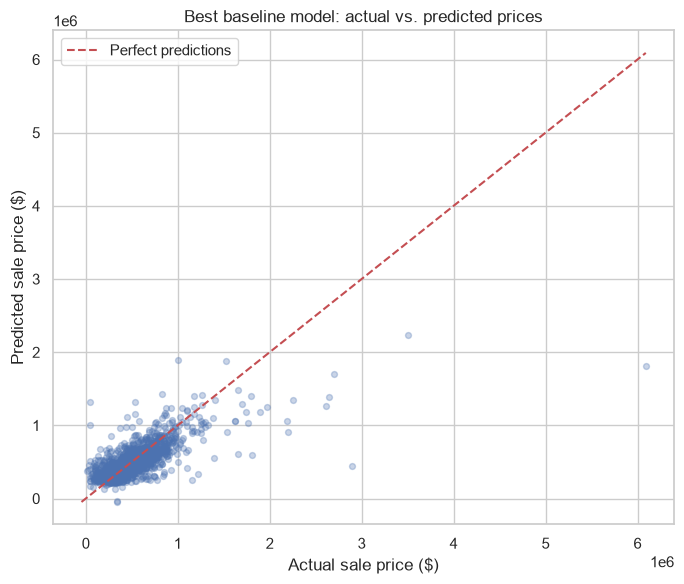

In [44]:
# A final check: predictions from the selected model vs. real prices.
best = fitted_models[best_model_name]
best_features = models[best_model_name]
final_predictions = best.predict(X_test[best_features])

plt.figure(figsize=(7, 6))
plt.scatter(y_test, final_predictions, alpha=0.3, s=18)
min_value = min(y_test.min(), final_predictions.min())
max_value = max(y_test.max(), final_predictions.max())
plt.plot([min_value, max_value], [min_value, max_value], "r--", label="Perfect predictions")
plt.xlabel("Actual sale price ($)")
plt.ylabel("Predicted sale price ($)")
plt.title("Best baseline model: actual vs. predicted prices")
plt.legend()
plt.tight_layout()
plt.show()

The first model, which only uses house size, has a test RMSE of approximately 199,925.75 dollars and a test R² of 0.309. Adding bedrooms, bathrooms, and construction year improves the test RMSE to about 194,217.61 dollars and the test R² to 0.348. The third model, which includes the other numeric and categorical housing features, does considerably better: its training RMSE is about 158,681.87 dollars (R² = 0.542) and its test RMSE is about $161,845.10 (R² = 0.547).

I would choose Model 3 because it has the lowest five-fold cross-validation RMSE on the training data (about $166,382.74) and also performs best on the test set. This suggests that more than just square footage matters for sale prices, including features like bathrooms, garages, and recorded waterfront or view categories. The training and test results are fairly close, which is encouraging, although the prediction errors are still large in dollar terms. These are only baseline linear models, and some unusual high-price sales may be especially hard to predict.

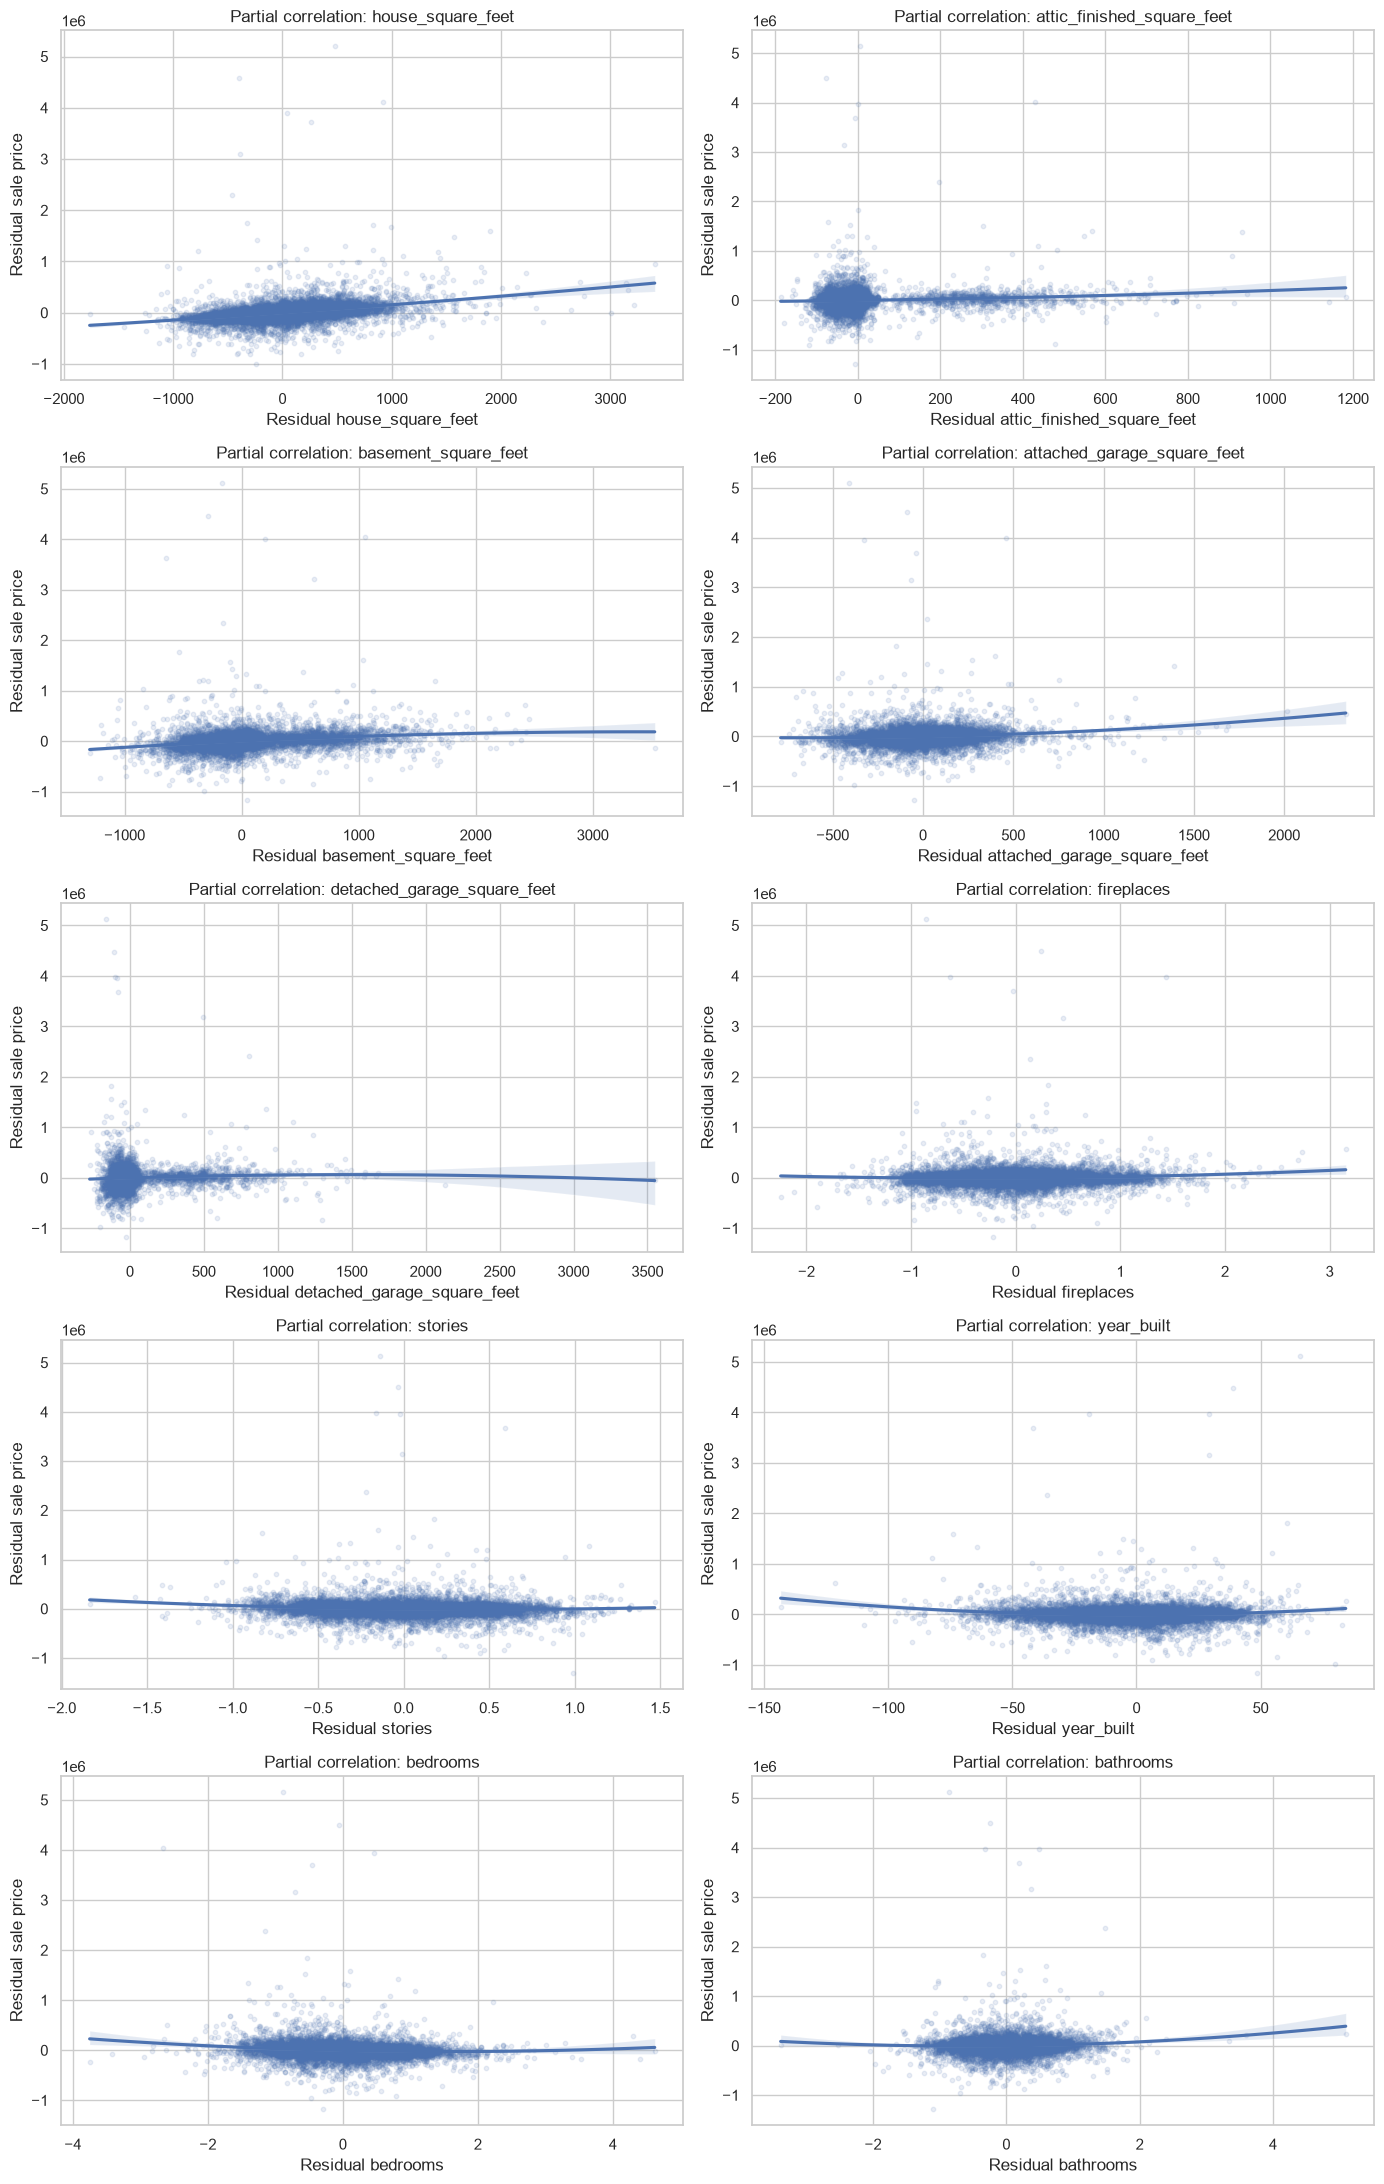

In [45]:
# Question 5: Partial correlation plots

fig, axes = plt.subplots(5, 2, figsize=(14, 22))
axes = axes.flatten()

all_features = list(X.columns)

for i, var in enumerate(numeric_cols):
    other_features = [col for col in all_features if col != var]

    # Residuals for sale price after controlling for the other variables
    y_model = make_linear_model(other_features)
    y_model.fit(X_train[other_features], y_train)
    y_resid = y_train - y_model.predict(X_train[other_features])

    # Residuals for this predictor after controlling for the other variables
    x_model = make_linear_model(other_features)
    x_model.fit(X_train[other_features], X_train[var])
    x_resid = X_train[var] - x_model.predict(X_train[other_features])

    sns.regplot(
        x=x_resid,
        y=y_resid,
        order=2,
        scatter_kws={"alpha": 0.12, "s": 10},
        ax=axes[i]
    )

    axes[i].set_title(f"Partial correlation: {var}")
    axes[i].set_xlabel(f"Residual {var}")
    axes[i].set_ylabel("Residual sale price")

plt.tight_layout()
plt.show()

The partial correlation plots show some evidence of nonlinear relationships between the numeric variables and sale price. House square footage has a strong positive relationship with price, but the fitted line shows some curvature. Attached garage square footage and bathrooms also show upward curvature. Year built and bedrooms have more noticeable U-shaped patterns, suggesting that their effects may not be completely linear. Other variables, such as basement square footage, attic finished square footage, fireplaces, and stories, show weaker nonlinear patterns. Overall, the plots suggest that adding transformations or interaction terms could improve the model compared with using only simple linear relationships.

In [46]:
# Question 6: More complex model with transformations and interactions

from sklearn.preprocessing import PolynomialFeatures, StandardScaler

numeric_transformer = Pipeline([
    ("scale", StandardScaler()),
    ("poly", PolynomialFeatures(
        degree=2,
        include_bias=False
    ))
])

complex_preprocessor = ColumnTransformer([
    (
        "numeric",
        numeric_transformer,
        numeric_cols
    ),
    (
        "categorical",
        OneHotEncoder(
            drop="first",
            handle_unknown="ignore"
        ),
        categorical_cols
    )
])

complex_model = Pipeline([
    ("preprocessor", complex_preprocessor),
    ("regression", LinearRegression())
])

complex_model.fit(X_train, y_train)

complex_train_pred = complex_model.predict(X_train)
complex_test_pred = complex_model.predict(X_test)

complex_train_rmse = np.sqrt(
    mean_squared_error(y_train, complex_train_pred)
)

complex_test_rmse = np.sqrt(
    mean_squared_error(y_test, complex_test_pred)
)

complex_train_r2 = r2_score(
    y_train,
    complex_train_pred
)

complex_test_r2 = r2_score(
    y_test,
    complex_test_pred
)

print("Complex Model")
print("Train RMSE: ${:,.2f}".format(complex_train_rmse))
print("Train R²: {:.3f}".format(complex_train_r2))
print("Test RMSE: ${:,.2f}".format(complex_test_rmse))
print("Test R²: {:.3f}".format(complex_test_r2))

Complex Model
Train RMSE: $150,128.79
Train R²: 0.590
Test RMSE: $157,521.68
Test R²: 0.571


In [47]:
print("\nBest Simple Model")
print(
    results_df.loc[
        "Model 3: All features"
    ]
)


Best Simple Model
Train RMSE ($)        158531.366401
Train R2                   0.542727
Test RMSE ($)         161929.497289
Test R2                    0.546590
5-fold CV RMSE ($)    166410.411659
Name: Model 3: All features, dtype: float64


The more complex model improved on the simpler linear models. It had a training RMSE of about $150,129 and a training \(R^2\) of 0.590. On the test set, the RMSE was about \$157,522 and the \(R^2\) was 0.571. In comparison, the best simple model had a test RMSE of about \$162,113 and a test \(R^2\) of 0.546. This means that adding quadratic terms and interactions helped the model capture more of the relationship between the housing features and sale price. The training and test results are still fairly close, so the added complexity does not appear to cause severe overfitting.

Q7. Overall, the results show that housing prices depend on several property characteristics, not just house size. The simple model using only house square footage had the weakest performance, while adding more numeric and categorical variables improved both RMSE and \(R^2\). The partial correlation plots showed that some relationships were not completely linear, which motivated adding quadratic terms and interactions in the more complex model. The complex model performed better than the best simple model, with a lower test RMSE of about \$157,522 and a higher test \(R^2\) of 0.571 compared with about \$162,113 and 0.546 for the simple model. The training and test results were also fairly close, so there was not strong evidence of severe overfitting. This showed me that a more complex model can improve performance when the added complexity reflects real patterns in the data, but model selection should still be based on performance on unseen test data rather than training performance alone.

In [48]:
# Question 8: Lasso regression

from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler

lasso_preprocessor = ColumnTransformer([
    (
        "numeric",
        StandardScaler(),
        numeric_cols
    ),
    (
        "categorical",
        OneHotEncoder(
            drop="first",
            handle_unknown="ignore"
        ),
        categorical_cols
    )
])

lasso_pipeline = Pipeline([
    ("preprocessor", lasso_preprocessor),
    ("lasso", Lasso(max_iter=50000))
])

alpha_grid = {
    "lasso__alpha": np.logspace(2, 5, 12)
}

lasso_search = GridSearchCV(
    lasso_pipeline,
    param_grid=alpha_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

lasso_search.fit(X_train, y_train)

best_lasso = lasso_search.best_estimator_

lasso_train_pred = best_lasso.predict(X_train)
lasso_test_pred = best_lasso.predict(X_test)

lasso_train_rmse = np.sqrt(
    mean_squared_error(y_train, lasso_train_pred)
)

lasso_test_rmse = np.sqrt(
    mean_squared_error(y_test, lasso_test_pred)
)

lasso_train_r2 = r2_score(
    y_train,
    lasso_train_pred
)

lasso_test_r2 = r2_score(
    y_test,
    lasso_test_pred
)

print("Best alpha:", lasso_search.best_params_["lasso__alpha"])
print("Train RMSE: ${:,.2f}".format(lasso_train_rmse))
print("Train R²: {:.3f}".format(lasso_train_r2))
print("Test RMSE: ${:,.2f}".format(lasso_test_rmse))
print("Test R²: {:.3f}".format(lasso_test_r2))

Best alpha: 187.3817422860383
Train RMSE: $160,154.28
Train R²: 0.533
Test RMSE: $160,377.88
Test R²: 0.555


In [49]:
# Features selected by Lasso

preprocessor = best_lasso.named_steps["preprocessor"]

feature_names = preprocessor.get_feature_names_out()

coefficients = best_lasso.named_steps["lasso"].coef_

lasso_features = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

selected_features = lasso_features[
    lasso_features["Coefficient"] != 0
].copy()

selected_features["Absolute Coefficient"] = (
    selected_features["Coefficient"].abs()
)

selected_features = selected_features.sort_values(
    "Absolute Coefficient",
    ascending=False
)

print(
    "Features selected:",
    len(selected_features),
    "out of",
    len(feature_names)
)

display(selected_features.head(20))

Features selected: 34 out of 58


,Feature,Coefficient,Absolute Coefficient
29,categorical__exterior_Not recorded,1.363910e+06,1.363910e+06
44,categorical__waterfront_type_WF Salt,5.392217e+05,5.392217e+05
26,categorical__exterior_Log,3.410032e+05,3.410032e+05
42,categorical__waterfront_type_WF Lake,3.133410e+05,3.133410e+05
53,categorical__view_quality_View V-Good,2.616335e+05,2.616335e+05
22,categorical__exterior_Frame Rustic Log,2.291550e+05,2.291550e+05
47,categorical__view_quality_View Avg +,1.516275e+05,1.516275e+05
56,categorical__utility_sewer_SEWER/SEPTIC NO,-1.444354e+05,1.444354e+05
0,numeric__house_square_feet,1.175574e+05,1.175574e+05
48,categorical__view_quality_View Good,9.234323e+04,9.234323e+04


The Lasso model selected a subset of the available housing features by shrinking some coefficients toward zero. The best regularization value was an alpha of about 187.38. The model had a training RMSE of about \$160,154 and a training \(R^2\) of 0.533. On the test set, the RMSE was about \$160,378 and the \(R^2\) was 0.555. Some of the strongest selected predictors included exterior type, waterfront type, view quality, house square footage, and basement square footage. The Lasso model performed slightly better than the original simple all-features model on the test set, but not quite as well as the more complex polynomial model from Question 6. This shows that regularization can simplify the model by focusing on the more useful predictors while still maintaining similar predictive performance.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** b98929a
- **AI tool and model used:** Chat GPT-6

### *Prompts used

1. make more efficient
2. make more efficient

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. You can make this cleaner by using .assign() less, avoiding the explicit loop where possible, and simplifying the filtering and reporting.
More efficient version
#Remove exact duplicates

df = raw.drop_duplicates().copy()
after_duplicates = len(df)

#Filter invalid observations
valid = (    df["sale_date"].notna()    & df["sale_price"].gt(0)    & df["house_square_feet"].ge(200)    & df["stories"].between(1, 3)    & df["year_built"].between(1800, df["sale_date"].dt.year)    & df["bedrooms"].between(0, 10)    & df["bathrooms"].between(0, 8))

df = df.loc[valid].copy()

#Replace missing or blank categorical values
categorical_cols = df.select_dtypes(include=["object", "string"]).columns

df[categorical_cols] = (    df[categorical_cols]    .astype("string")    .apply(lambda col: col.str.strip())    .replace("", pd.NA)    .fillna("Not recorded"))

#Standardize HVAC descriptions

df["hvac_description"] = df["hvac_description"].replace(    "Floor Wall Furnace", "Floor/Wall Furnace")

#Print cleaning summary

print(f"Original rows: {len(raw):,}")
print(f"Exact duplicates removed: {len(raw) - after_duplicates:,}")
print(f"Additional invalid rows removed: {after_duplicates - len(df):,}")
print(f"Rows remaining: {len(df):,}")
print(f"Missing values remaining: {df.isna().sum().sum():,}")
print(f"Median price: ${df['sale_price'].median():,.0f}")print(f"Mean price: ${df['sale_price'].mean():,.0f}")

display(    df[["sale_price", "house_square_feet", "bedrooms", "bathrooms", "year_built"]]    .describe()    .round(1))

What I changed
1. Simplified comparisons: Used .gt() and .ge() instead of > and >=. These are pandas comparison methods and make the filtering consistent.
2. Simplified categorical cleaning: Used .apply() to strip whitespace across all categorical columns instead of explicitly looping through each column.
3. Simplified replacement: Replaced the HVAC dictionary with direct old-value/new-value arguments.
4. Simplified printing: Used f-strings instead of .format().
5. Kept .copy(): This helps avoid pandas SettingWithCopyWarning when modifying the filtered DataFrame.
One important note: Your original code and this version perform essentially the same cleaning. The biggest improvement is readability, not necessarily a major speed increase. For a large housing dataset, the filtering and duplicate removal will likely account for most of the processing time.

You can make this more concise by using cross? No need for additional functions here—just simplify the pipeline and calculate the evaluation metrics together.
More efficient version
#Question 6: Complex model with transformations and interactions

from sklearn.preprocessing import PolynomialFeatures, StandardScaler

#Preprocessing: scale numeric features and create quadratic terms

numeric_transformer = Pipeline([    ("scale", StandardScaler()),    ("poly", PolynomialFeatures(degree=2, include_bias=False))])

preprocessor = ColumnTransformer([    ("numeric", numeric_transformer, numeric_cols),    ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_cols)])

#Build and fit model

complex_model = Pipeline([    ("preprocessor", preprocessor),    ("regression", LinearRegression())])

complex_model.fit(X_train, y_train)

#Generate predictions

train_pred = complex_model.predict(X_train)
test_pred = complex_model.predict(X_test)

#Evaluate performance
for name, actual, predicted in [    
    ("Train", y_train, train_pred),    ("Test", y_test, test_pred)]:    
    print(f"{name} RMSE: ${mean_squared_error(actual, predicted) ** 0.5:,.2f}")    print(f"{name} R²: {r2_score(actual, predicted):.3f}")

What I changed
1. Combined metric calculations: Instead of creating four separate variables, calculate RMSE and R² directly when printing.
2. Removed redundant variable names: train_pred and test_pred are sufficient because the model is already named complex_model.
3. Simplified preprocessing: Removed unnecessary line breaks while preserving the same transformations.
4. Used a loop for evaluation: Avoided repeating nearly identical code for training and testing.
One important modeling detail
Your polynomial transformation creates:
- Squared terms (e.g., square footage²).
- Interaction terms (e.g., square footage × bedrooms).
- The original numeric features.
StandardScaler makes the numeric variables comparable in scale before generating these terms.

One thing to watch: PolynomialFeatures(degree=2) only creates interactions between numeric features. It does not create interactions between numeric and categorical features. Also, with many numeric variables, the number of features can grow quickly.

2. You can simplify this by using a loop for the evaluation metrics, just like your previous complex model. You can also define the preprocessing pipeline more compactly.
More efficient version
from sklearn.linear_model import Lasso

from sklearn.model_selection import GridSearchCV

from sklearn.preprocessing import StandardScaler

#Preprocessing

lasso_preprocessor = ColumnTransformer([    ("numeric", StandardScaler(), numeric_cols),    ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_cols)])

#Build Lasso pipeline

lasso_pipeline = Pipeline([    ("preprocessor", lasso_preprocessor),    ("lasso", Lasso(max_iter=50000))])

#Tune alpha using 5-fold cross-validation

lasso_search = GridSearchCV(    lasso_pipeline,    {"lasso__alpha": np.logspace(2, 5, 12)},    cv=5,    scoring="neg_root_mean_squared_error",    n_jobs=-1)

lasso_search.fit(X_train, y_train)

best_lasso = lasso_search.best_estimator_

#Generate predictions

train_pred = best_lasso.predict(X_train)
test_pred = best_lasso.predict(X_test)

#Evaluate model

print(f"Best alpha: {lasso_search.best_params_['lasso__alpha']:.2f}")

for name, actual, predicted in [    (
    "Train", y_train, train_pred),    ("Test", y_test, test_pred)]:
        print(f"{name} RMSE: ${mean_squared_error(actual, predicted) ** 0.5:,.2f}")    print(f"{name} R²: {r2_score(actual, predicted):.3f}")

What I changed
1. Removed unnecessary line breaks in the preprocessing pipeline.
2. Passed the alpha grid directly into GridSearchCV instead of creating a separate dictionary.
3. Combined the four evaluation calculations into one loop.
4. Used f-strings for cleaner output.
One recommendation about your Lasso model
Your alpha grid ranges from 100 to 100,000. That's a fairly large range, so make sure the best alpha isn't consistently at the smallest or largest value.

If it is, expand your search in that direction. Also, because you're using standardized numeric features and one-hot encoded categorical features, you're making Lasso's regularization more comparable across predictors.

Important: Lasso can shrink coefficients to exactly zero, which makes it useful for identifying which housing characteristics contribute the most to predicting sale prices. Keep in mind that this indicates predictive usefulness, not necessarily causation.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | **Accept** / modify / reject | The edits were predominantly consolidating the code with a for loop so it uses relatively the same code but in a more efficient way.|
| 2 | **Accept** / modify / reject | The edits were predominantly consolidating the code with a for loop so it uses relatively the same code but in a more efficient way. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [50]:
# Your Phase 2 solution to the problem goes here.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

raw = pd.read_csv("pierce_county_house_sales.csv")
raw["sale_date"] = pd.to_datetime(raw["sale_date"], errors="coerce")
print("Original shape:", raw.shape)
display(raw.head())

Original shape: (16814, 19)


,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,interior,stories,roof_cover,year_built,bedrooms,bathrooms,waterfront_type,view_quality,utility_sewer
0,2020-01-02,380000,2157,0,0,528,0,0,Warm and Cool Air Zone,Frame Siding,Drywall,2,Composition Shingle,1993,3,3,NaN,NaN,SEWER/SEPTIC INSTALLED
1,2020-01-02,383000,2238,0,0,396,0,0,Forced Air,Frame Siding,Drywall,2,Composition Shingle,2017,4,3,NaN,NaN,SEWER/SEPTIC INSTALLED
2,2020-01-01,419900,1452,0,0,0,0,1,Forced Air,Frame Siding,Drywall,1,Built Up Rock,1965,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED
3,2020-01-02,251660,832,0,0,0,0,0,Forced Air,Frame Vinyl,Drywall,1,Composition Shingle,1919,2,1,NaN,NaN,SEWER/SEPTIC INSTALLED
4,2020-01-02,500000,1780,0,384,484,0,1,Forced Air,Frame Siding,Drywall,1,Composition Shingle,1955,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED


In [51]:
print("Exact duplicate rows:", raw.duplicated().sum())
print("\nMissing values by column:")
display(raw.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

print("\nNumeric summary before cleaning:")
display(raw.describe().round(1))

Exact duplicate rows: 46

Missing values by column:


,missing_count
waterfront_type,16261
view_quality,15895
roof_cover,8
hvac_description,7
interior,7
exterior,1
sale_date,0
house_square_feet,0
sale_price,0
detached_garage_square_feet,0



Numeric summary before cleaning:


,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,stories,year_built,bedrooms,bathrooms
count,16814,16814.0,16814.0,16814.0,16814.0,16814.0,16814.0,16814.0,16814.0,16814.0,16814.0,16814.0
mean,2020-07-16 13:34:32.986796,461233.2,1879.9,24.9,167.9,364.4,38.3,0.9,1.6,1980.5,3.3,2.3
min,2020-01-01 00:00:00,2000.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1880.0,0.0,0.0
25%,2020-04-27 00:00:00,348000.0,1320.0,0.0,0.0,0.0,0.0,1.0,1.0,1959.0,3.0,2.0
50%,2020-07-27 00:00:00,416500.0,1774.0,0.0,0.0,420.0,0.0,1.0,2.0,1990.0,3.0,2.0
75%,2020-10-09 00:00:00,523806.5,2352.0,0.0,0.0,528.0,0.0,1.0,2.0,2006.0,4.0,3.0
max,2020-12-31 00:00:00,6130000.0,9510.0,1212.0,4000.0,2816.0,3664.0,5.0,3.0,2021.0,25.0,8.0
std,NaN,236083.3,760.4,102.1,429.1,286.5,164.7,0.6,0.5,33.3,0.9,0.8


In [52]:
df = raw.drop_duplicates().copy()
after_duplicates = len(df)

valid = (
        df["sale_date"].notna()
        & (df["sale_price"] > 0)
        & (df["house_square_feet"] >= 200)
        & df["stories"].between(1, 3)
        & df["year_built"].between(1800, df["sale_date"].dt.year)
        & df["bedrooms"].between(0, 10)
        & df["bathrooms"].between(0, 8)
)
df = df.loc[valid].copy()

# Turn blank categories into a real label rather than deleting most of the data.
categorical_cols = df.select_dtypes(
    include=["object", "string"]
).columns

df[categorical_cols] = (
    df[categorical_cols]
    .astype("string")
    .apply(lambda col: col.str.strip())
    .replace("", pd.NA)
    .fillna("Not recorded")
)

df["hvac_description"] = df["hvac_description"].replace(
    {"Floor Wall Furnace": "Floor/Wall Furnace"}
)

print("Original rows:", len(raw))
print("Exact duplicates removed:", len(raw) - after_duplicates)
print("Additional invalid rows removed:", after_duplicates - len(df))
print("Rows remaining:", len(df))
print("Missing values remaining:", df.isna().sum().sum())
print("Median price: ${:,.0f}".format(df["sale_price"].median()))
print("Mean price: ${:,.0f}".format(df["sale_price"].mean()))

display(df[["sale_price", "house_square_feet", "bedrooms", "bathrooms", "year_built"]].describe().round(1))

Original rows: 16814
Exact duplicates removed: 46
Additional invalid rows removed: 83
Rows remaining: 16685
Missing values remaining: 0
Median price: $416,000
Mean price: $460,909


,sale_price,house_square_feet,bedrooms,bathrooms,year_built
count,16685.0,16685.0,16685.0,16685.0,16685.0
mean,460909.2,1877.9,3.3,2.3,1980.2
std,235671.4,759.1,0.9,0.8,33.3
min,2000.0,200.0,0.0,0.0,1880.0
25%,348000.0,1318.0,3.0,2.0,1958.0
50%,416000.0,1773.0,3.0,2.0,1990.0
75%,523000.0,2348.0,4.0,3.0,2006.0
max,6130000.0,9510.0,9.0,8.0,2020.0


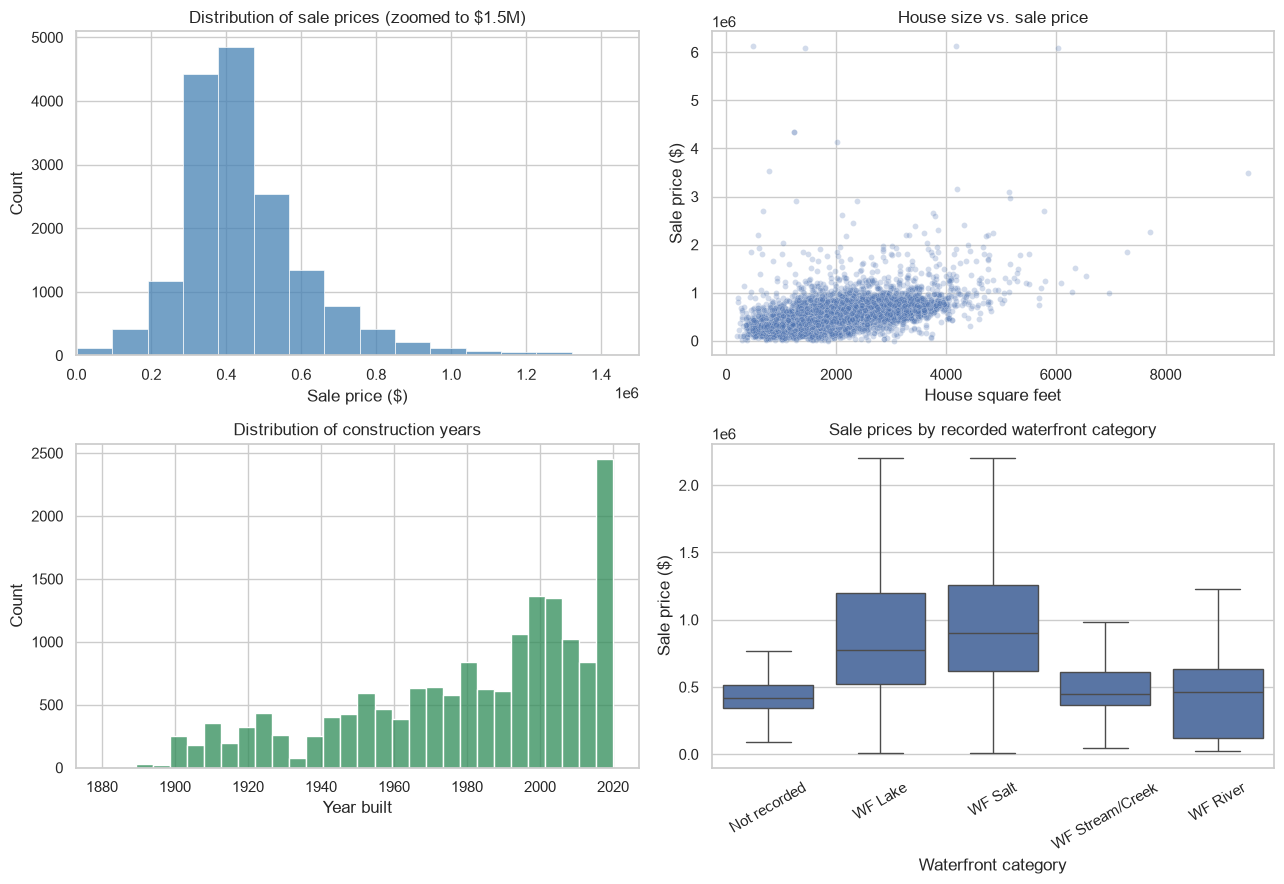

In [53]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

sns.histplot(df["sale_price"], bins=65, ax=axes[0, 0], color="steelblue")
axes[0, 0].set_xlim(0, 1_500_000)
axes[0, 0].set_title("Distribution of sale prices (zoomed to $1.5M)")
axes[0, 0].set_xlabel("Sale price ($)")

sns.scatterplot(data=df, x="house_square_feet", y="sale_price", ax=axes[0, 1],
                alpha=0.25, s=18)
axes[0, 1].set_title("House size vs. sale price")
axes[0, 1].set_xlabel("House square feet")
axes[0, 1].set_ylabel("Sale price ($)")

sns.histplot(df["year_built"], bins=30, ax=axes[1, 0], color="seagreen")
axes[1, 0].set_title("Distribution of construction years")
axes[1, 0].set_xlabel("Year built")

sns.boxplot(data=df, x="waterfront_type", y="sale_price", showfliers=False,
            ax=axes[1, 1])
axes[1, 1].set_title("Sale prices by recorded waterfront category")
axes[1, 1].set_xlabel("Waterfront category")
axes[1, 1].set_ylabel("Sale price ($)")
axes[1, 1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.savefig("pierce_county_phase1_eda.png", dpi=150, bbox_inches="tight")
plt.show()

In [54]:
print("Correlations with sale price (numeric variables):")
correlations = df.select_dtypes(include="number").corr()["sale_price"].sort_values(ascending=False)
display(correlations.to_frame("correlation_with_price").round(3))

print("Number of sales and median price for each waterfront category:")
display(df.groupby("waterfront_type")["sale_price"].agg(["count", "median"]).round(0))

Correlations with sale price (numeric variables):


,correlation_with_price
sale_price,1.000
house_square_feet,0.529
bathrooms,0.412
fireplaces,0.349
attached_garage_square_feet,0.312
basement_square_feet,0.271
year_built,0.230
bedrooms,0.209
stories,0.172
detached_garage_square_feet,0.053


Number of sales and median price for each waterfront category:


,count,median
waterfront_type,,
Not recorded,16136,415000.0
WF Lake,225,775000.0
WF River,26,462500.0
WF Salt,205,900000.0
WF Stream/Creek,93,450000.0


In [55]:
target_col = "sale_price"
X = df.drop(columns=[target_col, "sale_date"])
y = df[target_col]

numeric_cols = X.select_dtypes(include="number").columns.tolist()
categorical_cols = X.select_dtypes(
    include=["object", "string"]
).columns.tolist()

print("Target:", target_col)
print("Numeric predictors:", numeric_cols)
print("Categorical predictors:", categorical_cols)
print("Total original predictors:", X.shape[1])

Target: sale_price
Numeric predictors: ['house_square_feet', 'attic_finished_square_feet', 'basement_square_feet', 'attached_garage_square_feet', 'detached_garage_square_feet', 'fireplaces', 'stories', 'year_built', 'bedrooms', 'bathrooms']
Categorical predictors: ['hvac_description', 'exterior', 'interior', 'roof_cover', 'waterfront_type', 'view_quality', 'utility_sewer']
Total original predictors: 17


In [56]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))
print("Training percent: {:.1f}%".format(100 * len(X_train) / len(X)))
print("Test percent: {:.1f}%".format(100 * len(X_test) / len(X)))
assert len(X_train) + len(X_test) == len(X)
assert set(X_train.index).isdisjoint(set(X_test.index))

Training observations: 13348
Test observations: 3337
Training percent: 80.0%
Test percent: 20.0%


In [57]:
import warnings

warnings.filterwarnings(
    "ignore",
    message=r"Found unknown categories in columns .*",
    category=UserWarning,
    module=r"sklearn\.preprocessing\._encoders"
)

models = {
    "Model 1: Size only": ["house_square_feet"],
    "Model 2: Basic features": ["house_square_feet", "bedrooms", "bathrooms", "year_built"],
    "Model 3: All features": list(X.columns),
}

# This helper uses only dummy encoding for categories, with numeric data untouched.
def make_linear_model(feature_names):
    cat_features = [col for col in feature_names if col in categorical_cols]
    num_features = [col for col in feature_names if col in numeric_cols]
    steps = [("numeric", "passthrough", num_features)]
    if cat_features:
        steps.append((
            "categorical",
            OneHotEncoder(drop="first", handle_unknown="ignore"),
            cat_features
        ))
    preprocessor = ColumnTransformer(steps)
    return Pipeline([
        ("preprocessor", preprocessor),
        ("regression", LinearRegression())
    ])

cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = {}
for name, features in models.items():
    model = make_linear_model(features)
    scores = cross_val_score(
        model, X_train[features], y_train,
        cv=cv, scoring="neg_root_mean_squared_error"
    )
    cv_scores[name] = -scores.mean()

best_model_name = min(cv_scores, key=cv_scores.get)
print("Training-only 5-fold validation RMSE:")
for name, value in cv_scores.items():
    print("  {}: ${:,.2f}".format(name, value))
print("\nChosen by validation RMSE:", best_model_name)

Training-only 5-fold validation RMSE:
  Model 1: Size only: $199,122.56
  Model 2: Basic features: $195,536.45
  Model 3: All features: $166,410.41

Chosen by validation RMSE: Model 3: All features


In [58]:
# Evaluate each pre-specified model on the exact same train/test split.
results = []
fitted_models = {}

for name, features in models.items():
    model = make_linear_model(features)
    model.fit(X_train[features], y_train)
    fitted_models[name] = model

    pred_train = model.predict(X_train[features])
    pred_test = model.predict(X_test[features])

    results.append({
        "Model": name,
        "Train RMSE ($)": np.sqrt(mean_squared_error(y_train, pred_train)),
        "Train R2": r2_score(y_train, pred_train),
        "Test RMSE ($)": np.sqrt(mean_squared_error(y_test, pred_test)),
        "Test R2": r2_score(y_test, pred_test),
        "5-fold CV RMSE ($)": cv_scores[name]
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(3))

print("Best model:", best_model_name)
print("Test RMSE: ${:,.2f}".format(results_df.loc[best_model_name, "Test RMSE ($)"]))
print("Test R²: {:.3f}".format(results_df.loc[best_model_name, "Test R2"]))

,Train RMSE ($),Train R2,Test RMSE ($),Test R2,5-fold CV RMSE ($)
Model,,,,,
Model 1: Size only,200036.872,0.272,199925.753,0.309,199122.558
Model 2: Basic features,196319.887,0.299,194217.607,0.348,195536.448
Model 3: All features,158531.366,0.543,161929.497,0.547,166410.412


Best model: Model 3: All features
Test RMSE: $161,929.50
Test R²: 0.547


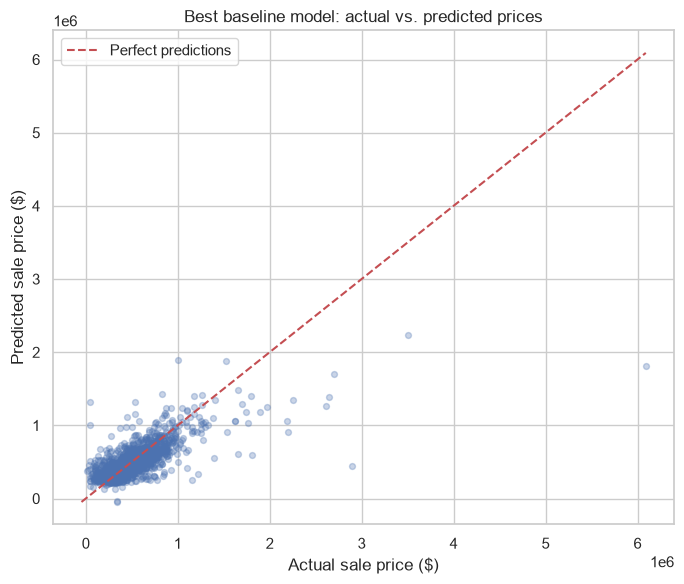

In [59]:
# A final check: predictions from the selected model vs. real prices.
best = fitted_models[best_model_name]
best_features = models[best_model_name]
final_predictions = best.predict(X_test[best_features])

plt.figure(figsize=(7, 6))
plt.scatter(y_test, final_predictions, alpha=0.3, s=18)
min_value = min(y_test.min(), final_predictions.min())
max_value = max(y_test.max(), final_predictions.max())
plt.plot([min_value, max_value], [min_value, max_value], "r--", label="Perfect predictions")
plt.xlabel("Actual sale price ($)")
plt.ylabel("Predicted sale price ($)")
plt.title("Best baseline model: actual vs. predicted prices")
plt.legend()
plt.tight_layout()
plt.show()

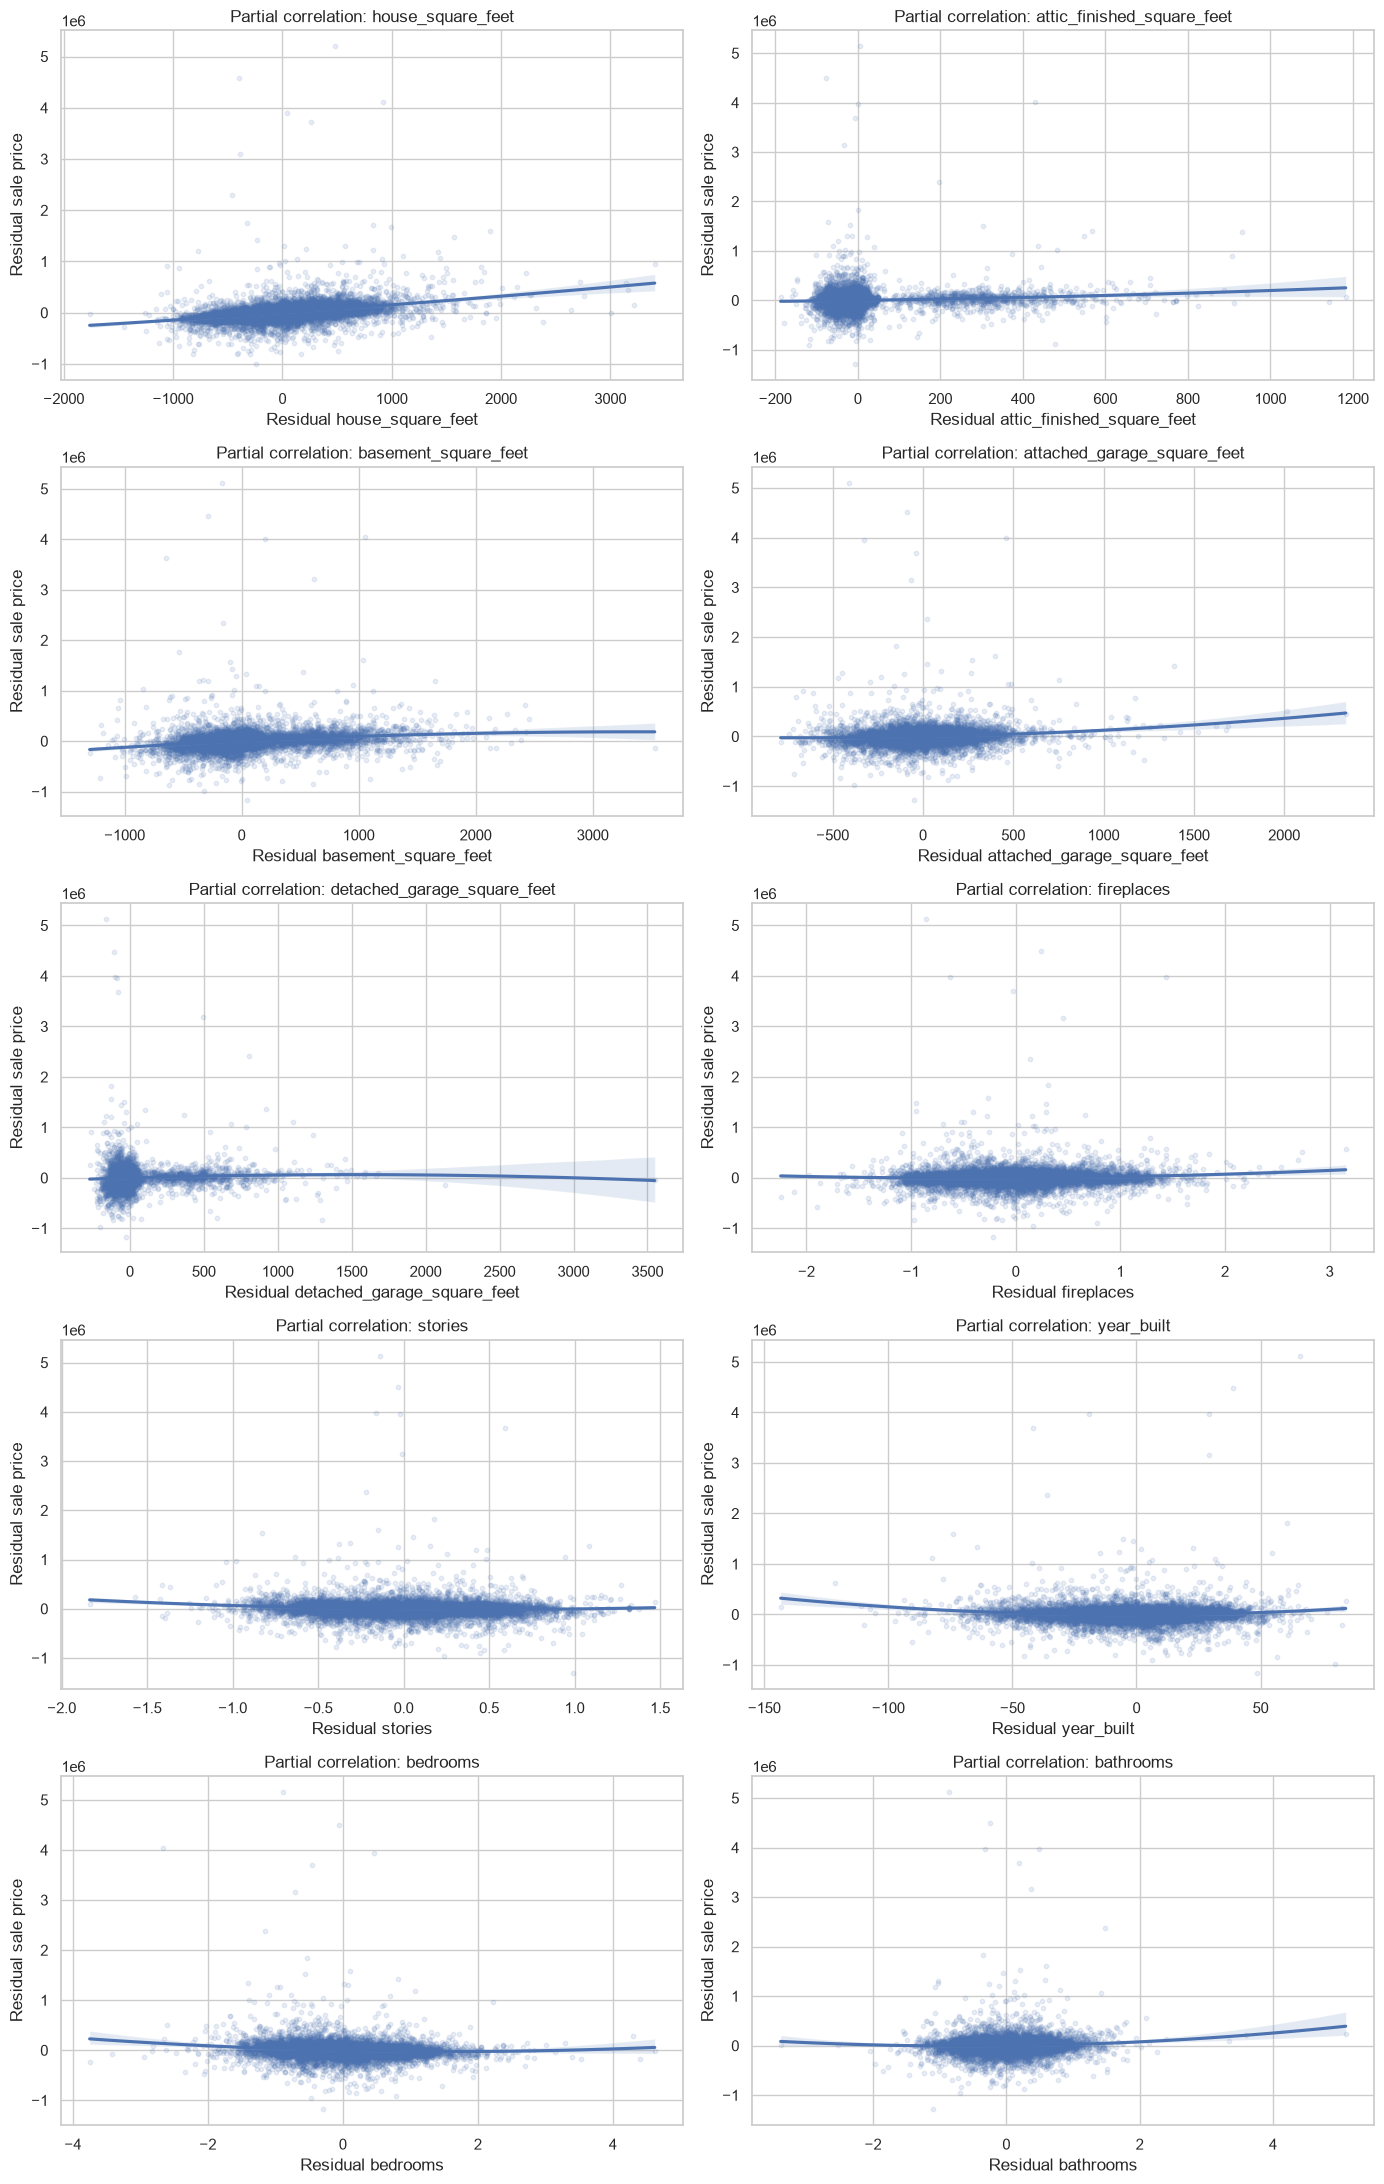

In [60]:
# Question 5: Partial correlation plots

fig, axes = plt.subplots(5, 2, figsize=(14, 22))
axes = axes.flatten()

all_features = list(X.columns)

for i, var in enumerate(numeric_cols):
    other_features = [col for col in all_features if col != var]

    # Residuals for sale price after controlling for the other variables
    y_model = make_linear_model(other_features)
    y_model.fit(X_train[other_features], y_train)
    y_resid = y_train - y_model.predict(X_train[other_features])

    # Residuals for this predictor after controlling for the other variables
    x_model = make_linear_model(other_features)
    x_model.fit(X_train[other_features], X_train[var])
    x_resid = X_train[var] - x_model.predict(X_train[other_features])

    sns.regplot(
        x=x_resid,
        y=y_resid,
        order=2,
        scatter_kws={"alpha": 0.12, "s": 10},
        ax=axes[i]
    )

    axes[i].set_title(f"Partial correlation: {var}")
    axes[i].set_xlabel(f"Residual {var}")
    axes[i].set_ylabel("Residual sale price")

plt.tight_layout()
plt.show()

In [61]:
# Question 6: More complex model with transformations and interactions

from sklearn.preprocessing import PolynomialFeatures, StandardScaler

numeric_transformer = Pipeline([
    ("scale", StandardScaler()),
    ("poly", PolynomialFeatures(
        degree=2,
        include_bias=False
    ))
])

complex_preprocessor = ColumnTransformer([
    (
        "numeric",
        numeric_transformer,
        numeric_cols
    ),
    (
        "categorical",
        OneHotEncoder(
            drop="first",
            handle_unknown="ignore"
        ),
        categorical_cols
    )
])

complex_model = Pipeline([
    ("preprocessor", complex_preprocessor),
    ("regression", LinearRegression())
])

complex_model.fit(X_train, y_train)

complex_train_pred = complex_model.predict(X_train)
complex_test_pred = complex_model.predict(X_test)

for name, actual, predicted in [
    ("Train", y_train, complex_train_pred),
    ("Test", y_test, complex_test_pred)
]:
    print(f"{name} RMSE: ${mean_squared_error(actual, predicted) ** 0.5:,.2f}")
    print(f"{name} R²: {r2_score(actual, predicted):.3f}")


Train RMSE: $150,128.79
Train R²: 0.590
Test RMSE: $157,521.68
Test R²: 0.571


In [62]:
print("\nBest Simple Model")
print(
    results_df.loc[
        "Model 3: All features"
    ]
)


Best Simple Model
Train RMSE ($)        158531.366401
Train R2                   0.542727
Test RMSE ($)         161929.497289
Test R2                    0.546590
5-fold CV RMSE ($)    166410.411659
Name: Model 3: All features, dtype: float64


In [63]:
# Question 8: Lasso regression

from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler

lasso_preprocessor = ColumnTransformer([
    (
        "numeric",
        StandardScaler(),
        numeric_cols
    ),
    (
        "categorical",
        OneHotEncoder(
            drop="first",
            handle_unknown="ignore"
        ),
        categorical_cols
    )
])

lasso_pipeline = Pipeline([
    ("preprocessor", lasso_preprocessor),
    ("lasso", Lasso(max_iter=50000))
])

lasso_search = GridSearchCV(
    lasso_pipeline,
    param_grid=alpha_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

lasso_search.fit(X_train, y_train)

best_lasso = lasso_search.best_estimator_

lasso_train_pred = best_lasso.predict(X_train)
lasso_test_pred = best_lasso.predict(X_test)

print(f"Best alpha: {lasso_search.best_params_['lasso__alpha']:.2f}")

for name, actual, predicted in [
    ("Train", y_train, lasso_train_pred),
    ("Test", y_test, lasso_test_pred)
]:
    print(f"{name} RMSE: ${mean_squared_error(actual, predicted) ** 0.5:,.2f}")
    print(f"{name} R²: {r2_score(actual, predicted):.3f}")

Best alpha: 187.38
Train RMSE: $160,154.28
Train R²: 0.533
Test RMSE: $160,377.88
Test R²: 0.555


In [64]:
# Features selected by Lasso

preprocessor = best_lasso.named_steps["preprocessor"]

feature_names = preprocessor.get_feature_names_out()

coefficients = best_lasso.named_steps["lasso"].coef_

lasso_features = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

selected_features = lasso_features[
    lasso_features["Coefficient"] != 0
].copy()

selected_features["Absolute Coefficient"] = (
    selected_features["Coefficient"].abs()
)

selected_features = selected_features.sort_values(
    "Absolute Coefficient",
    ascending=False
)

print(
    "Features selected:",
    len(selected_features),
    "out of",
    len(feature_names)
)

display(selected_features.head(20))

Features selected: 34 out of 58


,Feature,Coefficient,Absolute Coefficient
29,categorical__exterior_Not recorded,1.363910e+06,1.363910e+06
44,categorical__waterfront_type_WF Salt,5.392217e+05,5.392217e+05
26,categorical__exterior_Log,3.410032e+05,3.410032e+05
42,categorical__waterfront_type_WF Lake,3.133410e+05,3.133410e+05
53,categorical__view_quality_View V-Good,2.616335e+05,2.616335e+05
22,categorical__exterior_Frame Rustic Log,2.291550e+05,2.291550e+05
47,categorical__view_quality_View Avg +,1.516275e+05,1.516275e+05
56,categorical__utility_sewer_SEWER/SEPTIC NO,-1.444354e+05,1.444354e+05
0,numeric__house_square_feet,1.175574e+05,1.175574e+05
48,categorical__view_quality_View Good,9.234323e+04,9.234323e+04


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

I used Chat GPT-6 to help make some of my group's code more efficient when it came to graphing and giving test vs training results. Since our original code was rather intuitive, effective, and answered each part of the questions, there wasn't much the generative AI could consolidate or make more efficient. However, after prompting the model, the AI recommended I use for loops, the apply method, and the lambda keyword to cut down some lines of code. Since it didn't change much of our code, I was less hesitant to add in the recommendations. I verified the final solution by rerunning the new code to make sure no errors came up. The AI didn't introduce any code I wasn't familiar with so I didn't have to do extra research. Finally, I compared the graphical and machine learning model results to those of Phase 1 to make sure they were the same. 